# When expectations change perceived time

Hold a stimulus on screen for 0.9 s. Among intervals that are mostly shorter, it seems long. Among
intervals that are mostly longer, it seems short. Asked to reproduce it, people press a key for
different lengths of time, although the physical interval never changed.

This tutorial follows that observation as deep as one model can take it.

**Part I · Foundations** builds the inference tools: Bayes' rule in log odds, how people fall short
of it, the product of two Gaussians, Weber's law from Fisher information, and neurons that add log
likelihoods. It uses the probability grids of Foundations 10, the spiking neurons of Foundations 11,
and the Fisher information of Foundations 12.

**Part II · Case study** takes the context effect through six stages:

| stage | question |
|---|---|
| 1. Cognitive phenomenon | What exactly needs explaining? |
| 2. Behavioral experiment | How do we make it measurable? |
| 3. Empirical signature | What pattern in the data is the phenomenon? |
| 4. Computational model | What minimal computation produces that pattern, and can we identify its parameters? |
| 5. Neural implementation | Could spiking neurons carry out that computation? |
| 6. Prediction and failure | Which experiment could prove the model wrong? |

**About the data.** Stages 2 to 6 use data simulated from a model whose parameters we chose. That is
deliberate: with known ground truth we can check whether each analysis recovers it. Stage 6 then
confronts the model with real reproduction data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
colors = {"short context": "#2563eb", "long context": "#dc2626"}
rng = np.random.default_rng(12)

# Part I · Foundations

## 1. Bayes' rule in log odds

When there are only two hypotheses, Bayes' rule is easiest in **log odds**. Take two urns. Urn A
holds 70 percent red balls, urn B 30 percent. One urn is picked, balls are drawn with replacement,
and the question is which urn it was.

$$\underbrace{\log\frac{P(A \mid x_{1:n})}{P(B \mid x_{1:n})}}_{\text{posterior log odds}}
= \underbrace{\log\frac{P(A)}{P(B)}}_{\text{prior log odds}}
+ \sum_{t=1}^{n} \underbrace{\log\frac{p(x_t \mid A)}{p(x_t \mid B)}}_{\text{evidence of draw } t}.$$

| symbol | meaning | array | shape |
|---|---|---|---|
| $x_t$ | color of draw $t$ (1 = red) | `draws` | (n_seq, n_draws) |
| $\log p(x_t\mid A)/p(x_t\mid B)$ | how much one draw favors A: $\pm\log(0.7/0.3)$ | `llr` | (n_seq, n_draws) |
| posterior log odds | the belief after $n$ draws | `post_lo` | (n_seq, n_draws) |

Belief becomes a running sum. Each draw adds its evidence, independently of all the others.

In [2]:
n_seq, n_draws = 2000, 10
is_A = rng.random(n_seq) < 0.5                                     # (n_seq,) which urn was used
draws = rng.random((n_seq, n_draws)) < np.where(is_A, 0.7, 0.3)[:, None]   # (n_seq, n_draws) red = True
llr = np.where(draws, np.log(0.7 / 0.3), np.log(0.3 / 0.7))        # (n_seq, n_draws) evidence per draw
prior_lo = 0.0                                                     # equal prior
post_lo = prior_lo + llr.cumsum(axis=1)                            # (n_seq, n_draws) running belief

acc = ((post_lo > 0) == is_A[:, None]).mean(axis=0) + 0.5 * (post_lo == 0).mean(axis=0)
print("accuracy of the sign of the belief after 1..10 draws:", acc.round(2))

accuracy of the sign of the belief after 1..10 draws: [0.71 0.7  0.78 0.8  0.84 0.84 0.88 0.88 0.9  0.91]


## 2. Conservatism: people move less than Bayes

In tasks like this, people's stated beliefs move in the right direction but not far enough
(Phillips & Edwards, 1966). Grether (1980) measured it with a regression on reported log odds:

$$\text{reported log odds} = \alpha \cdot \text{evidence} + \beta \cdot \text{prior log odds} + \text{noise}.$$

A Bayesian has $\alpha = \beta = 1$. Typical estimates have $\alpha < 1$: evidence is
underweighted.

One way to produce this is a **tempered likelihood**: the observer raises the likelihood to a power
below 1 before combining it with the prior,

$$q(s \mid x) \propto p(x \mid s)^{1/(1+\lambda)}\, p(s).$$

In log odds this simply multiplies the evidence by $\alpha = 1/(1+\lambda)$. It also follows from a
cost on changing one's mind: if moving a belief far from the prior is penalized in proportion to the
KL divergence, with weight $\lambda$, the optimal compromise is exactly this tempered posterior. We
simulate a conservative observer with $\lambda = 1$ and check that the regression recovers
$\alpha = 0.5$.

In [3]:
lam = 1.0
prior_p = rng.choice([0.3, 0.5, 0.7], n_seq)                        # (n_seq,) announced prior for A
prior_lo_t = np.log(prior_p / (1 - prior_p))
evidence = llr[:, :5].sum(axis=1)                                   # (n_seq,) five draws
reported = evidence / (1 + lam) + prior_lo_t + rng.normal(0, 0.3, n_seq)   # (n_seq,) noisy report

X = np.column_stack([evidence, prior_lo_t])                         # (n_seq, 2)
(alpha_hat, beta_hat), *_ = np.linalg.lstsq(X, reported, rcond=None)
print(f"alpha = {alpha_hat:.3f} (true {1 / (1 + lam):.3f}),  beta = {beta_hat:.3f} (true 1.000)")

alpha = 0.501 (true 0.500),  beta = 0.992 (true 1.000)


## 3. Two Gaussians make a Gaussian

For continuous quantities like duration, the workhorse is a Gaussian prior combined with a Gaussian
likelihood. With measurement $m$, likelihood $\mathcal N(m; s, \sigma_s^2)$ and prior
$\mathcal N(s; \mu_p, \sigma_p^2)$, the log posterior is

$$\log p(s \mid m) = -\frac{(m - s)^2}{2\sigma_s^2} - \frac{(s - \mu_p)^2}{2\sigma_p^2} + \text{const}.$$

That is a quadratic in $s$, so the posterior is Gaussian. Setting the derivative to zero gives its
mean, and the curvature gives its variance:

$$\hat s = w\,m + (1 - w)\,\mu_p, \qquad w = \frac{\sigma_p^2}{\sigma_s^2 + \sigma_p^2}, \qquad
\sigma_\text{post}^2 = \Big(\frac{1}{\sigma_s^2} + \frac{1}{\sigma_p^2}\Big)^{-1}.$$

Precisions (inverse variances) add, and the mean is a precision weighted average. We check both
formulas against a brute force grid posterior, as in Foundations 10.

In [4]:
s_grid13 = np.linspace(-1, 3, 4001)                                 # (K,) candidate durations
m_obs, sig_s, mu_p, sig_p = 1.2, 0.16, 0.9, 0.20
post = norm.pdf(m_obs, s_grid13, sig_s) * norm.pdf(s_grid13, mu_p, sig_p)   # (K,) likelihood x prior
post /= post.sum()
w = sig_p**2 / (sig_s**2 + sig_p**2)
print(f"posterior mean: grid {post @ s_grid13:.4f}, formula {w * m_obs + (1 - w) * mu_p:.4f}")
print(f"posterior SD:   grid {np.sqrt(post @ (s_grid13 - post @ s_grid13) ** 2):.4f}, "
      f"formula {(1 / sig_s**2 + 1 / sig_p**2) ** -0.5:.4f}")

posterior mean: grid 1.0829, formula 1.0829
posterior SD:   grid 0.1249, formula 0.1249


The estimate is pulled from the measurement toward the prior mean by a fraction $1 - w$. Averaged
over measurements, the bias at duration $s$ is $(1 - w)(\mu_p - s)$: positive for short durations,
negative for long ones. That is the central tendency, written as one line.

## 4. Weber's law from Fisher information

How does $\sigma_s$ depend on the duration? Foundations 11 and 12 gave two routes to the same
answer: a bank of log spaced time constants, or an efficient code in a scale free world, both
produce Fisher information $J(s) \propto 1/s^2$. A measurement that is Gaussian on a log scale,
$\log m \sim \mathcal N(\log s, \sigma_w^2)$, has exactly that:

$$J(s) = \frac{1}{\sigma_w^2 s^2}, \qquad \text{threshold} \propto \frac{1}{\sqrt{J(s)}} = \sigma_w\, s.$$

Real timing usually adds a part that does not scale, from motor output or from a noisy start and
stop. The two parts add as variances, giving the **generalized Weber law**:

$$\sigma^2(s) = \sigma_0^2 + (k\,s)^2.$$

For short durations the constant part dominates and the coefficient of variation (CV $= \sigma/s$)
is large. For long durations the scalar part dominates and the CV levels off at $k$.

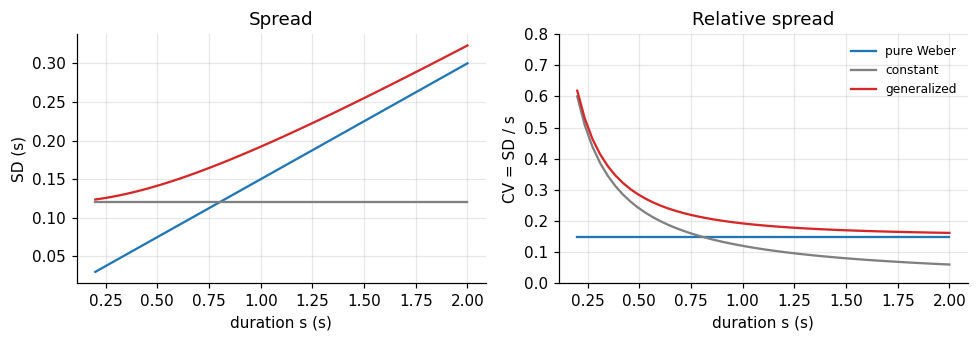

In [5]:
s_range = np.linspace(0.2, 2.0, 50)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for (sig0, k), col, name in [((0.0, 0.15), "C0", "pure Weber"), ((0.12, 0.0), "0.5", "constant"),
                            ((0.12, 0.15), "C3", "generalized")]:
    sd = np.sqrt(sig0**2 + (k * s_range) ** 2)                      # (50,)
    axes[0].plot(s_range, sd, color=col, label=name)
    axes[1].plot(s_range, sd / s_range, color=col, label=name)
axes[0].set(xlabel="duration s (s)", ylabel="SD (s)", title="Spread")
axes[1].set(xlabel="duration s (s)", ylabel="CV = SD / s", title="Relative spread", ylim=(0, 0.8))
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The three noise laws make different predictions for both curves. Stage 6 uses this figure to read
real data.

## 5. Neurons that add log likelihoods

Section 1 showed belief as a sum of log likelihood ratios. A population of Poisson neurons gives
those ratios directly. To decide whether a duration was $A$ or $B$ from spike counts $n_i$:

$$\text{LLR} = \sum_i n_i \log\frac{f_i(A)}{f_i(B)} - \sum_i \big(f_i(A) - f_i(B)\big).$$

The first term is a weighted sum of spike counts with fixed synaptic weights $\log f_i(A)/f_i(B)$.
The second is a constant. A downstream neuron that sums its inputs with those weights computes the
log likelihood ratio. If spikes keep arriving, it keeps adding, exactly like the urn observer.
Neurons in monkey parietal cortex accumulate such evidence when each cue has a learned weight
(Yang & Shadlen, 2007).

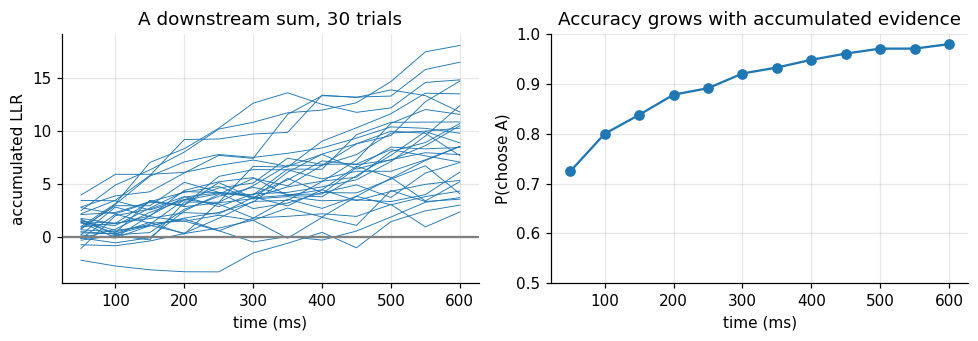

In [6]:
pref13 = np.linspace(0.2, 1.8, 40)                                  # (I,) preferred durations
f_rate = lambda s: 0.5 * np.exp(-0.5 * ((s - pref13) / 0.15) ** 2) + 0.05   # (I,) spikes per 50 ms bin
dA, dB = 0.85, 0.95                                                 # two similar durations
weights = np.log(f_rate(dA) / f_rate(dB))                           # (I,) synaptic weights
const = (f_rate(dA) - f_rate(dB)).sum()

n_bins, n_tr = 12, 2000
counts = rng.poisson(f_rate(dA), size=(n_tr, n_bins, pref13.size))   # (trials, bins, I), truth is A
llr_t = (counts @ weights - const).cumsum(axis=1)                    # (trials, bins) running LLR

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(np.arange(1, n_bins + 1) * 50, llr_t[:30].T, color="C0", lw=0.6)
axes[0].axhline(0, color="0.5")
axes[0].set(xlabel="time (ms)", ylabel="accumulated LLR", title="A downstream sum, 30 trials")
axes[1].plot(np.arange(1, n_bins + 1) * 50, (llr_t > 0).mean(axis=0), "o-", color="C0")
axes[1].set(xlabel="time (ms)", ylabel="P(choose A)", title="Accuracy grows with accumulated evidence",
            ylim=(0.5, 1))
plt.tight_layout()
plt.show()

### What Part I gives us

- With two hypotheses, belief is a running sum of log likelihood ratios.
- People often weight evidence by $\alpha < 1$; a tempered likelihood produces exactly that.
- Gaussian prior times Gaussian likelihood: precisions add, the mean is a weighted average.
- Log scale noise gives Weber's law; real timing often adds a constant part.
- Poisson neurons give log likelihood ratios as weighted spike counts.

# Part II · Case study: when expectations change perceived time

## Stage 1 · Cognitive phenomenon

Judgments of magnitude drift toward the middle of the range a person has recently experienced.
Short intervals are overestimated, long ones underestimated. Hollingworth (1910) called this the
*central tendency of judgment*; in timing research it is also known as Vierordt's law.

Two features make it a good first case:

- **It is about context, not the stimulus.** The same physical interval is judged differently
  depending on what else was shown.
- **It is graded.** People are not simply wrong. Their judgments still track the stimulus, only less
  steeply than they should.

A useful explanation must account for both: why judgments follow the stimulus, and why they are
pulled toward the context.

## Stage 2 · Behavioral experiment

**Task: temporal reproduction.** A disc appears for a duration $s$. After a short blank, the
participant presses and holds a key for as long as the disc was shown. The hold time is the
response $r$. Because $r$ is continuous, a single trial shows both the size and the direction of the
error.

**Manipulation: context.** Two blocks contain the same five *test* durations, 0.60 to 1.20 s. They
differ in their *filler* durations. Fillers in the short-context block are mostly short and fillers
in the long-context block are mostly long. Only test trials are analysed, so any difference between
blocks cannot come from the stimuli themselves.

**Controls.**

- Randomise trial order within a block; counterbalance block order across participants.
- Give practice trials so the key press itself is stable before the test begins.
- Analyse context as a block-level factor. Trials within a block are not independent samples of
  the manipulation.

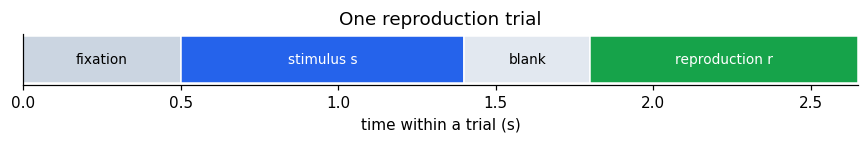

In [7]:
phases = [("fixation", 0.5, "#cbd5e1"), ("stimulus s", 0.9, "#2563eb"),
          ("blank", 0.4, "#e2e8f0"), ("reproduction r", 0.85, "#16a34a")]
fig, ax = plt.subplots(figsize=(8, 1.4))
t = 0
for label, dur, color in phases:
    ax.barh(0, dur, left=t, color=color, edgecolor="white")
    ax.text(t + dur / 2, 0, label, ha="center", va="center", fontsize=9,
            color="white" if color in ("#2563eb", "#16a34a") else "black")
    t += dur
ax.set(xlabel="time within a trial (s)", yticks=[], xlim=(0, t), title="One reproduction trial")
ax.grid(False)
plt.tight_layout()
plt.show()

The simulation below generates the test trials of 24 participants. Each block's durations define
what the observer comes to expect: a mean of 0.75 s in the short context and 1.05 s in the long
context. How the observer turns a measurement into a response is the model of Stage 4; here it simply
generates data. Each participant also gets a small constant offset, because people differ in how long
they tend to hold a key.

In [8]:
test_durations = np.array([0.60, 0.75, 0.90, 1.05, 1.20])
context_means = {"short context": 0.75, "long context": 1.05}
truth = {"sensory_sd": 0.16, "prior_sd": 0.20, "motor_sd": 0.045}

def simulate_observer(duration, prior_mean, sensory_sd, prior_sd, motor_sd, rng):
    m = duration + rng.normal(0, 1, len(duration)) * sensory_sd       # m | s ~ N(s, sigma_s^2)
    w = prior_sd**2 / (sensory_sd**2 + prior_sd**2)                     # weight on the measurement
    estimate = w * m + (1 - w) * prior_mean                             # posterior mean
    return estimate + rng.normal(0, motor_sd, len(duration))            # key press adds motor noise

def make_design(n_participants=24, reps=18, reliabilities=("clear",)):
    rows = [(p, c, mu, rel, d)
            for p in range(n_participants)
            for c, mu in context_means.items()
            for rel in reliabilities
            for d in test_durations
            for _ in range(reps)]
    return pd.DataFrame(rows, columns=["participant", "context", "prior_mean", "reliability", "duration"])

data = make_design()
offsets = rng.normal(0, 0.035, data["participant"].nunique())
data["response"] = simulate_observer(data["duration"].to_numpy(), data["prior_mean"].to_numpy(),
                                     rng=rng, **truth) + offsets[data["participant"]]
print(data.sample(5, random_state=1))
print(f"\n{len(data)} test trials: {data['participant'].nunique()} participants x 2 contexts x "
      f"5 durations x 18 repetitions")

      participant        context  prior_mean reliability  duration  response
2756           15  short context        0.75       clear      1.05  1.138000
2815           15   long context        1.05       clear      0.75  0.778377
1781            9   long context        1.05       clear      1.05  1.048250
3774           20   long context        1.05       clear      1.20  1.106640
2388           13  short context        0.75       clear      0.90  1.024063

4320 test trials: 24 participants x 2 contexts x 5 durations x 18 repetitions


## Stage 3 · Empirical signature

What should the phenomenon look like in this table? Average within each participant first, then
across participants, and look for three things:

1. responses still **increase** with the presented duration;
2. the response function is **shallower than the identity line** (central tendency);
3. at the **same** test duration, the long context gives **longer** responses (context shift).

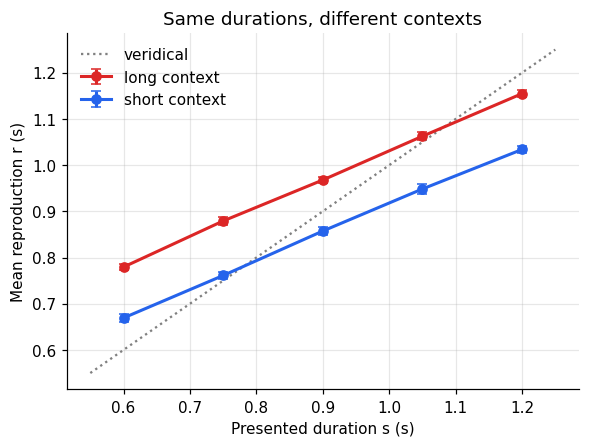

In [9]:
participant_means = data.groupby(["participant", "context", "duration"], as_index=False)["response"].mean()
summary = participant_means.groupby(["context", "duration"])["response"].agg(["mean", "sem"]).reset_index()

fig, ax = plt.subplots(figsize=(6, 4.2))
for context, g in summary.groupby("context"):
    ax.errorbar(g["duration"], g["mean"], yerr=g["sem"], marker="o", capsize=3, lw=2,
                color=colors[context], label=context)
ax.plot([0.55, 1.25], [0.55, 1.25], color="0.5", ls=":", label="veridical")
ax.set(xlabel="Presented duration s (s)", ylabel="Mean reproduction r (s)",
       title="Same durations, different contexts")
ax.legend(frameon=False)
plt.show()

All three features are present. Before proposing a mechanism, put numbers on them with a
description that makes no claims about mechanism:

$$r = \beta_0 + \beta_s\, s + \beta_c\, c + \varepsilon, \qquad c = -\tfrac12 \text{ (short)},\ +\tfrac12 \text{ (long)}.$$

- $\beta_s$: how strongly responses follow the stimulus. A value of 1 means no central tendency.
- $\beta_c$: how far, in seconds, the long context shifts responses relative to the short one.

In [10]:
c = data["context"].map({"short context": -0.5, "long context": 0.5}).to_numpy()
X = np.column_stack([np.ones(len(data)), data["duration"], c])      # columns: 1, s, c
beta, *_ = np.linalg.lstsq(X, data["response"].to_numpy(), rcond=None)
print(f"beta_s (duration slope) = {beta[1]:.3f}")
print(f"beta_c (context shift)  = {beta[2]:.3f} s")

beta_s (duration slope) = 0.617
beta_c (context shift)  = 0.115 s


The slope is about 0.6 and the context shift is over 100 ms. That is the signature. The regression
says nothing about *why* the slope is 0.6 or *why* the shift has this size. A model should explain
both with the same parameters.

## Stage 4 · Computational model

### The assumptions

The observer never sees $s$ directly. Every symbol below is something we could, in principle,
manipulate or measure:

| symbol | meaning | what changes it |
|---|---|---|
| $s$ | physical duration on this trial | the experimenter |
| $m$ | internal measurement of $s$ | sensory noise on each trial |
| $\sigma_s$ | how blurred the internal clock is | stimulus quality, attention |
| $\mu_p$ | mean duration the observer expects in this block | the context |
| $\sigma_p$ | how broad that expectation is | the spread of durations in the block |
| $w$ | weight given to the measurement | the ratio of $\sigma_s$ to $\sigma_p$ |
| $\sigma_m$ | motor noise of the key press | the response method |

Two assumptions turn this into a model:

$$m \mid s \sim \mathcal N(s, \sigma_s^2) \quad\text{(likelihood)}, \qquad s \sim \mathcal N(\mu_p, \sigma_p^2) \quad\text{(prior)}.$$

### The estimate

Part I, section 3, derived the posterior for exactly this pair of assumptions. Its mean is

$$\hat s = w\, m + (1 - w)\, \mu_p, \qquad w = \frac{\sigma_p^2}{\sigma_s^2 + \sigma_p^2}.$$

The estimate is a weighted average of what was measured and what was expected. The weight on the
measurement is high when the measurement is precise ($\sigma_s$ small) or the expectation is vague
($\sigma_p$ large).

### What it predicts for the data

The response adds motor noise: $r = \hat s + \varepsilon_m$, with $\varepsilon_m \sim \mathcal N(0, \sigma_m^2)$.
Averaging over $m$ gives the distribution of responses to a given duration:

$$r \mid s \sim \mathcal N\big(\underbrace{w\, s + (1-w)\,\mu_p}_{\text{mean}},\ \underbrace{w^2\sigma_s^2 + \sigma_m^2}_{\text{variance}}\big).$$

Compare this with the regression. The model **explains** both descriptive numbers with one quantity:

- the slope is $\beta_s = w$;
- the context shift is $\beta_c = (1 - w)(\mu_{\text{long}} - \mu_{\text{short}})$.

With $w \approx 0.6$ and a 0.3 s difference between context means, the shift should be about
$0.4 \times 0.3 = 0.12$ s, which is what the regression found.

### From equations to code

Each line of `predict` is one equation above. The likelihood of the data is the product of Gaussian
densities over trials; we minimise its negative logarithm. Standard deviations are optimised on a
log scale so they stay positive, and each fit starts from several points.

In [11]:
def predict(s, mu_p, sensory_sd, prior_sd, motor_sd, offset):
    w = prior_sd**2 / (sensory_sd**2 + prior_sd**2)          # w = sigma_p^2 / (sigma_s^2 + sigma_p^2)
    mean = w * s + (1 - w) * mu_p + offset                   # E[r | s] = w s + (1 - w) mu_p
    sd = np.sqrt((w * sensory_sd) ** 2 + motor_sd**2)        # Var[r | s] = w^2 sigma_s^2 + sigma_m^2
    return mean, sd

def unpack(theta, n_levels):
    # theta = [log sigma_s per reliability level..., log sigma_p, log sigma_m, offset]
    return np.exp(theta[:n_levels]), np.exp(theta[n_levels]), np.exp(theta[n_levels + 1]), theta[-1]

def bayes_nll(theta, frame, n_levels):
    sens, prior_sd, motor_sd, offset = unpack(theta, n_levels)
    level = frame["level"].to_numpy() if n_levels > 1 else np.zeros(len(frame), int)
    mean, sd = predict(frame["duration"].to_numpy(), frame["prior_mean"].to_numpy(),
                       sens[level], prior_sd, motor_sd, offset)
    return -norm.logpdf(frame["response"].to_numpy(), mean, sd).sum()

def fit_bayes(frame, n_levels=1, fixed_sensory=None):
    starts = [np.r_[np.log([a] * n_levels), np.log([b, 0.05]), 0.0]
              for a in (0.08, 0.15, 0.3) for b in (0.1, 0.25, 0.5)]
    if fixed_sensory is not None:           # profile: hold sigma_s, optimise the rest
        f = lambda th: bayes_nll(np.r_[np.log(fixed_sensory), th], frame, 1)
        best = min((minimize(f, s0[1:], method="Nelder-Mead", options={"maxiter": 4000})
                    for s0 in starts[:3]), key=lambda r: r.fun)
        return best
    f = lambda th: bayes_nll(th, frame, n_levels)
    return min((minimize(f, s0, method="Nelder-Mead", options={"maxiter": 6000}) for s0 in starts),
               key=lambda r: r.fun)

fit = fit_bayes(data)
sens, prior_sd, motor_sd, offset = unpack(fit.x, 1)
w_hat = prior_sd**2 / (sens[0]**2 + prior_sd**2)
w_true = truth["prior_sd"]**2 / (truth["sensory_sd"]**2 + truth["prior_sd"]**2)
sd_r_hat = np.sqrt((w_hat * sens[0]) ** 2 + motor_sd**2)                 # SD of responses at fixed s
sd_r_true = np.sqrt((w_true * truth["sensory_sd"]) ** 2 + truth["motor_sd"] ** 2)
print(f"{'':28s}{'fitted':>8s}{'true':>8s}")
print(f"{'w (weight on measurement)':28s}{w_hat:8.3f}{w_true:8.3f}")
print(f"{'response SD at fixed s':28s}{sd_r_hat:8.3f}{sd_r_true:8.3f}")
print(f"{'sigma_s':28s}{sens[0]:8.3f}{truth['sensory_sd']:8.3f}")
print(f"{'sigma_p':28s}{prior_sd:8.3f}{truth['prior_sd']:8.3f}")
print(f"{'sigma_m':28s}{motor_sd:8.3f}{truth['motor_sd']:8.3f}")

                              fitted    true
w (weight on measurement)      0.617   0.610
response SD at fixed s         0.111   0.107
sigma_s                        0.181   0.160
sigma_p                        0.229   0.200
sigma_m                        0.000   0.045


### Diagnosis: what is the experiment allowed to tell us?

The first two rows are recovered: the weight $w$ and the spread of responses. The three noise
terms are not. In this run the optimizer set $\sigma_m$ to zero and inflated $\sigma_s$ and
$\sigma_p$ by the same factor, which keeps their ratio and therefore $w$, so that $w^2\sigma_s^2$
alone carries all the response variance. The fit is as good as with the true parameters, yet the
three numbers mean nothing on their own. Count what the data constrain. The mean response pins down $w$, which depends only
on the **ratio** of $\sigma_s$ to $\sigma_p$. The response variance pins down one number,
$w^2\sigma_s^2 + \sigma_m^2$. That is two constraints on three noise parameters.

A **profile likelihood** makes this visible. Fix $\sigma_s$ at a value, let all other parameters adjust
to fit as well as they can, and record how bad the best fit is. A sharp valley means $\sigma_s$ is
identified. A flat floor means many values explain the data equally well.

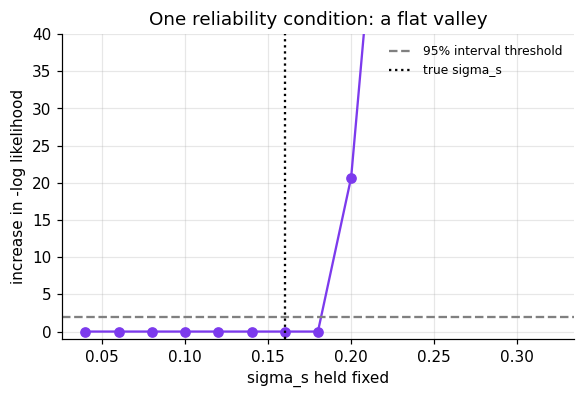

In [12]:
grid = np.linspace(0.04, 0.32, 15)
profile = np.array([fit_bayes(data, fixed_sensory=g).fun for g in grid])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(grid, profile - profile.min(), "o-", color="#7c3aed")
ax.axhline(1.92, color="0.5", ls="--", label="95% interval threshold")
ax.axvline(truth["sensory_sd"], color="k", ls=":", label="true sigma_s")
ax.set(xlabel="sigma_s held fixed", ylabel="increase in -log likelihood",
       title="One reliability condition: a flat valley", ylim=(-1, 40))
ax.legend(frameon=False, fontsize=8)
plt.show()

Every value of $\sigma_s$ whose curve lies under the dashed line is compatible with the data at
the 95% level. Small values fit as well as the true one: the model compensates by shrinking $\sigma_p$
to keep $w$ fixed and enlarging $\sigma_m$ to keep the variance fixed. With this design, a fitted
$\sigma_s$ should not be interpreted as "how noisy this person's clock is."

**The fix is a manipulation, not a better optimiser.** Add a second, noisier version of the stimulus
(for example a dimmer disc) in both contexts. Sensory noise now differs between conditions while the
prior and motor noise are shared. That gives four constraints (two weights, two variances) for four
noise parameters.

Parameter recovery shows the difference. Simulate 12 datasets with different true $\sigma_s$, fit
each, and compare the estimates with the truth under both designs.

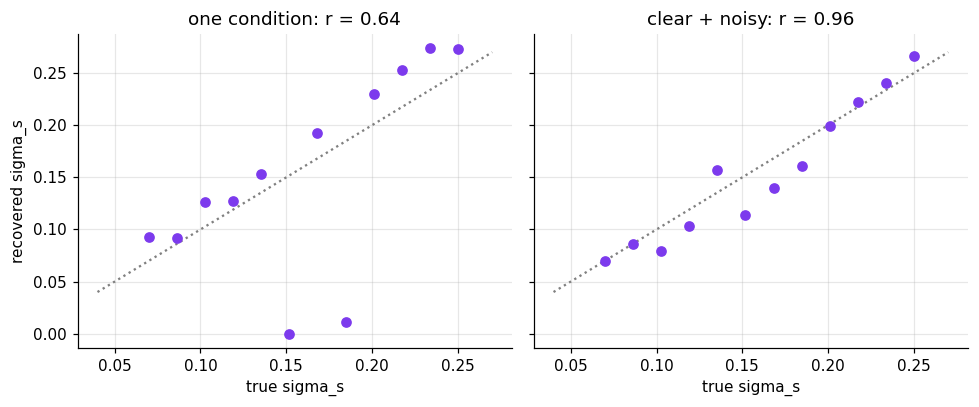

one condition  RMS recovery error = 0.070
clear + noisy  RMS recovery error = 0.019


In [13]:
def simulate_dataset(design, sensory_by_level, seed):
    r = np.random.default_rng(seed)
    d = design.copy()
    d["level"] = d["reliability"].map({"clear": 0, "noisy": 1}).astype(int)
    sd = np.asarray(sensory_by_level)[d["level"].to_numpy()]
    off = r.normal(0, 0.035, d["participant"].nunique())
    d["response"] = simulate_observer(d["duration"].to_numpy(), d["prior_mean"].to_numpy(), sd,
                                      truth["prior_sd"], truth["motor_sd"], r) + off[d["participant"]]
    return d

one_design = make_design(reliabilities=("clear",))
two_design = make_design(reliabilities=("clear", "noisy"), reps=9)    # same total trial count
true_values = np.linspace(0.07, 0.25, 12)
recovered = {"one condition": [], "clear + noisy": []}
for i, sd_true in enumerate(true_values):
    d1 = simulate_dataset(one_design, [sd_true], seed=200 + i)
    recovered["one condition"].append(unpack(fit_bayes(d1, 1).x, 1)[0][0])
    d2 = simulate_dataset(two_design, [sd_true, 2 * sd_true], seed=300 + i)
    recovered["clear + noisy"].append(unpack(fit_bayes(d2, 2).x, 2)[0][0])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, (name, est) in zip(axes, recovered.items()):
    ax.plot([0.04, 0.27], [0.04, 0.27], color="0.5", ls=":")
    ax.scatter(true_values, est, color="#7c3aed", zorder=3)
    r = np.corrcoef(true_values, est)[0, 1]
    ax.set(xlabel="true sigma_s", title=f"{name}: r = {r:.2f}")
axes[0].set_ylabel("recovered sigma_s")
plt.tight_layout()
plt.show()
for name, est in recovered.items():
    err = np.sqrt(np.mean((np.array(est) - true_values) ** 2))
    print(f"{name:14s} RMS recovery error = {err:.3f}")

With one condition, estimates are scattered or biased because the data cannot separate the noise
terms. With two reliability conditions and the same number of trials, they line up with the truth.
**The design, not the model, decides what can be learned.**

## Stage 5 · Neural implementation

The model of Stage 4 states a computation. It does not say how neurons would perform it. Here is one
way they could.

**A population of duration-tuned neurons.** Give each of 40 neurons a preferred duration and a
Gaussian tuning curve $f_i(s)$. On a trial, neuron $i$ emits a Poisson spike count $n_i$ with mean
$g\,f_i(s)$. The gain $g$ stands for stimulus quality: a clear stimulus drives the neurons strongly,
a dim one weakly.

**Calibrating the gain.** The population's Fisher information is $J = g\sum_i f_i'^2/f_i$
(Foundations 12). Its likelihood is as wide as the behavioral measurement noise when
$J = 1/\sigma_s^2$, so we set $g = 1/(\sigma_s^2 \sum_i f_i'^2/f_i)$. This ties the neural model to the
behavioral one with no free parameter.

**Reading out a posterior.** For independent Poisson neurons the log likelihood of a duration is a
weighted sum of spike counts,

$$\log p(\mathbf n \mid s) = \sum_i n_i \log f_i(s) - g \sum_i f_i(s) + \text{const}.$$

If the tuning curves tile the duration axis evenly, the second sum hardly depends on $s$. A
downstream area can then add the log prior for the current context and read out the posterior mean.
Nothing in the code below knows about $w$: the weighting of measurement against expectation emerges
from the spike counts.

gain clear 1.041, gain dim 0.260; expected spikes per trial at 0.9 s: 33.5 and 8.4


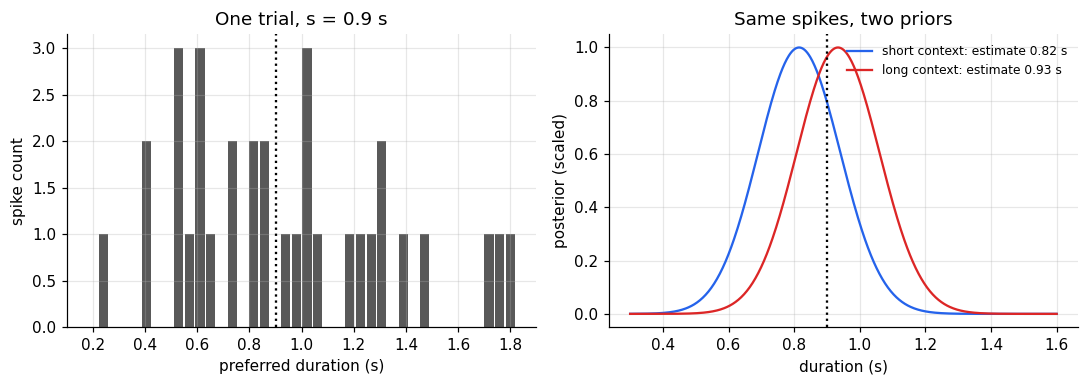

In [14]:
preferred = np.linspace(0.2, 1.8, 40)           # preferred durations, shape [neurons]
tuning_width = 0.6                               # broad duration tuning, in seconds
s_axis = np.linspace(0.3, 1.6, 600)             # durations the readout considers, shape [grid]

def tuning(s):
    return np.exp(-0.5 * ((np.asarray(s)[..., None] - preferred) / tuning_width) ** 2) + 0.05

def spikes(s, gain, n_trials, rng):
    return rng.poisson(gain * tuning(np.full(n_trials, s)))                # [trials, neurons]

def gain_for(sensory_sd, s=0.9):
    # Fisher information of the population is gain * sum f'^2 / f; set it to 1 / sensory_sd^2
    g = np.exp(-0.5 * ((s - preferred) / tuning_width) ** 2)
    f, df = g + 0.05, -g * (s - preferred) / tuning_width**2
    return 1 / (sensory_sd**2 * (df**2 / f).sum())


def decode(counts, gain, prior_mean, prior_sd=truth["prior_sd"]):
    F = gain * tuning(s_axis)                                              # [grid, neurons]
    log_like = counts @ np.log(F).T - F.sum(1)                             # [trials, grid]
    log_post = log_like + norm.logpdf(s_axis, prior_mean, prior_sd)        # add the context prior
    post = np.exp(log_post - log_post.max(1, keepdims=True))
    post /= post.sum(1, keepdims=True)
    return post @ s_axis, post                                             # posterior mean, posterior

gain_clear = gain_for(truth["sensory_sd"])                     # matches behavioral sigma_s = 0.16 s
gain_dim = gain_for(2 * truth["sensory_sd"])                   # a dimmer stimulus: twice the noise
print(f"gain clear {gain_clear:.3f}, gain dim {gain_dim:.3f}; expected spikes per trial at 0.9 s: "
      f"{(gain_clear * tuning(0.9)).sum():.1f} and {(gain_dim * tuning(0.9)).sum():.1f}")

n_one = spikes(0.9, gain=gain_clear, n_trials=1, rng=rng)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(preferred, n_one[0], width=0.035, color="0.35")
axes[0].axvline(0.9, color="k", ls=":")
axes[0].set(xlabel="preferred duration (s)", ylabel="spike count", title="One trial, s = 0.9 s")
for context, mu in context_means.items():
    est, post = decode(n_one, gain_clear, mu)
    axes[1].plot(s_axis, post[0] / post[0].max(), color=colors[context],
                 label=f"{context}: estimate {est[0]:.2f} s")
axes[1].axvline(0.9, color="k", ls=":")
axes[1].set(xlabel="duration (s)", ylabel="posterior (scaled)", title="Same spikes, two priors")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The same spike pattern yields two different estimates once the context prior is added. Now repeat
this over many trials at two gains. Fewer spikes make a broader likelihood, so the prior should pull
harder.

In [15]:
rows = []
for gain, label in [(gain_clear, "clear"), (gain_dim, "dim")]:
    for s in test_durations:
        counts = spikes(s, gain, 400, rng)
        for context, mu in context_means.items():
            rows.append((label, context, s, decode(counts, gain, mu)[0].mean()))
neural = pd.DataFrame(rows, columns=["gain", "context", "duration", "estimate"])
shift = (neural.pivot_table(index=["gain", "duration"], columns="context", values="estimate")
               .eval("`long context` - `short context`").groupby("gain").mean())
print("context shift of the decoded estimate (s):")
print(shift.round(3))
for label, sd_s in [("clear", truth["sensory_sd"]), ("dim", 2 * truth["sensory_sd"])]:
    w_ = truth["prior_sd"]**2 / (sd_s**2 + truth["prior_sd"]**2)
    print(f"Bayesian prediction, {label}: (1 - w) x 0.3 s = {(1 - w_) * 0.3:.3f} s")

context shift of the decoded estimate (s):
gain
clear    0.122
dim      0.222
dtype: float64
Bayesian prediction, clear: (1 - w) x 0.3 s = 0.117 s
Bayesian prediction, dim: (1 - w) x 0.3 s = 0.216 s


The decoded shifts match the Bayesian predictions closely: about 0.12 s for the clear stimulus
and nearly twice that for the dim one. The tuning width matters here. With narrow tuning curves, a
likelihood as broad as behavior would rest on one or two spikes per trial, the Gaussian
approximation behind the Fisher information would fail, and the decoded shift would overshoot.
Broad duration tuning keeps tens of spikes per trial at the same precision.
The context shift is larger when the gain is low. The population carries the reliability of the evidence in its total activity, and
a downstream readout that adds a prior weights the two correctly without being told how.
Ma, Beck, Latham and Pouget (2006) developed this idea as *probabilistic population codes*.

Three claims must be kept apart:

1. **Consistent with neural data.** Recordings in monkey medial premotor cortex show timing signals
   that change with the prior (Jazayeri & Shadlen, 2010, studied the behavioral side of this
   paradigm). Consistency does not mean the code above is used.
2. **Implementable.** The simulation shows spiking neurons *can* perform the computation. It does
   not show that they do.
3. **Causal.** Only perturbing the neurons and observing the predicted change in behavior would
   show that the brain relies on this mechanism.

This tutorial reaches level 2.

## Stage 6 · Prediction and failure

### A rival that fits the same data

A simpler account needs no probabilities. An **anchoring** observer mixes each stimulus with the
block mean using a fixed weight $a$:

$$r = a\,s + (1 - a)\,\mu_p + \varepsilon.$$

On the data of Stage 3 this is indistinguishable from the Bayesian observer: both give a slope
below 1 and a context shift of $(1 - a)(\mu_{\text{long}} - \mu_{\text{short}})$. A good fit to the
original experiment cannot tell them apart.

### The experiment that separates them

The models disagree about **reliability**. The Bayesian weight $w$ falls when the stimulus gets
noisier, so the context shift should grow. The anchoring weight $a$ is fixed, so the shift should
not change. The clear and noisy design of Stage 4 tests exactly this. Simulate it under each model.

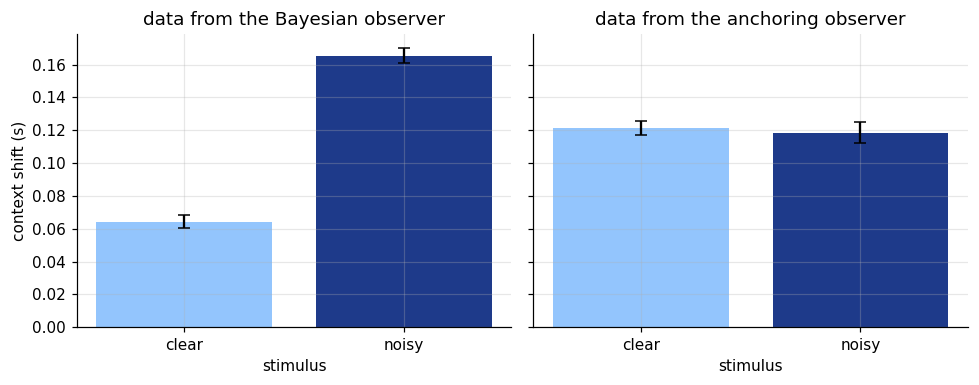

In [16]:
def simulate_anchoring(design, a, noise_by_level, seed):
    r = np.random.default_rng(seed)
    d = design.copy()
    d["level"] = d["reliability"].map({"clear": 0, "noisy": 1}).astype(int)
    noise = np.asarray(noise_by_level)[d["level"].to_numpy()]
    off = r.normal(0, 0.035, d["participant"].nunique())
    d["response"] = (a * d["duration"] + (1 - a) * d["prior_mean"]
                     + r.normal(0, 1, len(d)) * noise + off[d["participant"]])
    return d

bayes_data = simulate_dataset(two_design, [0.10, 0.22], seed=7)
anchor_data = simulate_anchoring(two_design, a=0.6, noise_by_level=[0.10, 0.15], seed=7)

def context_shift(d):
    m = d.groupby(["participant", "reliability", "context"])["response"].mean().unstack("context")
    return (m["long context"] - m["short context"]).groupby("reliability").agg(["mean", "sem"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (name, d) in zip(axes, [("data from the Bayesian observer", bayes_data),
                                ("data from the anchoring observer", anchor_data)]):
    cs = context_shift(d).loc[["clear", "noisy"]]
    ax.bar(cs.index, cs["mean"], yerr=cs["sem"], capsize=4, color=["#93c5fd", "#1e3a8a"])
    ax.set(title=name, xlabel="stimulus")
axes[0].set_ylabel("context shift (s)")
plt.tight_layout()
plt.show()

The prediction is qualitative and easy to see. The Bayesian observer's context shift roughly doubles
for the noisy stimulus; the anchoring observer's does not change.

To decide between the models formally, fit both and compare how well they predict participants they
were **not** fitted to. We fit on half of the participants and score the log likelihood of the other
half. As a check of the procedure itself (*model recovery*), we do this for data generated by each
model: the comparison should pick the generating model in both cases.

In [17]:
def anchoring_nll(theta, frame):
    a = 1 / (1 + np.exp(-theta[0]))                  # weight a in (0, 1)
    offset = theta[1]
    noise = np.exp(theta[2:4])[frame["level"].to_numpy()]
    mean = a * frame["duration"] + (1 - a) * frame["prior_mean"] + offset
    return -norm.logpdf(frame["response"], mean, noise).sum()

def fit_anchoring(frame):
    starts = [np.array([x, 0.0, np.log(0.1), np.log(0.15)]) for x in (-1.0, 0.4, 1.5)]
    return min((minimize(anchoring_nll, s0, args=(frame,), method="Nelder-Mead",
                         options={"maxiter": 4000}) for s0 in starts), key=lambda r: r.fun)

def held_out_comparison(d):
    train = d[d["participant"] < 12]
    test = d[d["participant"] >= 12]
    bayes = bayes_nll(fit_bayes(train, 2).x, test, 2)
    anchor = anchoring_nll(fit_anchoring(train).x, test)
    return bayes, anchor

for name, d in [("Bayesian", bayes_data), ("anchoring", anchor_data)]:
    b, a = held_out_comparison(d)
    winner = "Bayesian" if b < a else "anchoring"
    print(f"data from {name:9s}: held-out -log L  Bayesian {b:8.1f}  anchoring {a:8.1f}  -> prefers {winner}")

data from Bayesian : held-out -log L  Bayesian  -1808.8  anchoring  -1647.8  -> prefers Bayesian


data from anchoring: held-out -log L  Bayesian  -1334.1  anchoring  -1411.2  -> prefers anchoring


### Where the model fails on real data

The models above were tested on data they generated. Real data are less polite. Take the reproduction
experiment from notebook 3 (16 participants, durations 0.5 to 1.7 s, from
[msenselab/working_memory_reproduction](https://github.com/msenselab/working_memory_reproduction)).
The Gaussian observer predicts that the **spread** of reproductions is the same at every duration,
because $w^2\sigma_s^2 + \sigma_m^2$ does not depend on $s$.

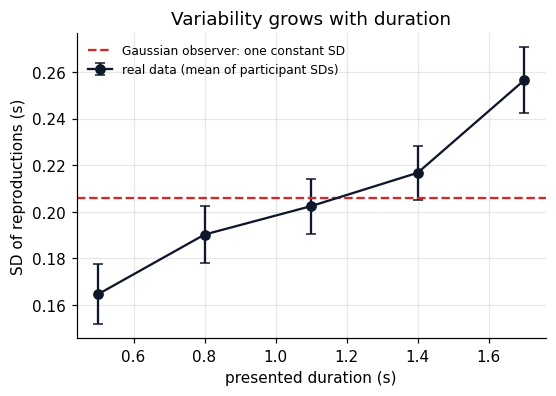

           SD     CV
curDur              
0.5     0.165  0.329
0.8     0.190  0.238
1.1     0.202  0.184
1.4     0.217  0.155
1.7     0.256  0.151
generalized Weber fit: sigma_0 = 0.157 s, k = 0.116


In [18]:
URL = ("https://raw.githubusercontent.com/msenselab/working_memory_reproduction/"
       "HEAD/data/AllValidData.csv")
real = pd.read_csv(URL).query("Exp == 'Exp1'")
spread = (real.groupby(["NSub", "curDur"])["repDur"].std()
              .groupby("curDur").agg(["mean", "sem"]))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.errorbar(spread.index, spread["mean"], yerr=spread["sem"], marker="o", capsize=3,
            color="#0f172a", label="real data (mean of participant SDs)")
ax.axhline(spread["mean"].mean(), color="#dc2626", ls="--",
           label="Gaussian observer: one constant SD")
ax.set(xlabel="presented duration (s)", ylabel="SD of reproductions (s)",
       title="Variability grows with duration")
ax.legend(frameon=False, fontsize=8)
plt.show()
print(pd.DataFrame({"SD": spread["mean"], "CV": spread["mean"] / spread.index}).round(3))

# Generalized Weber law: SD^2 = sigma_0^2 + (k s)^2, a straight line in s^2
slope_k2, sig0_2 = np.polyfit(spread.index.to_numpy() ** 2, spread["mean"].to_numpy() ** 2, 1)
print(f"generalized Weber fit: sigma_0 = {np.sqrt(max(sig0_2, 0)):.3f} s, k = {np.sqrt(max(slope_k2, 0)):.3f}")

The standard deviation grows from about 0.17 s to 0.26 s across the range, so the constant noise
assumption of the model is wrong. But the spread is not proportional to the duration either: the CV
falls from about 0.33 to 0.15. Compare with the figure in Part I, section 4. The data look like the
**generalized** Weber law, a constant part plus a scalar part, and the fit gives both. The mean
predictions of the model can look right while its variance is systematically wrong.

The repair keeps the Bayesian logic and changes the likelihood: let the measurement noise follow
$\sigma^2(s) = \sigma_0^2 + (k s)^2$. The posterior then has no closed form, but it can be computed on a
grid exactly as the neural readout in Stage 5 did. That repaired model makes new predictions, for
example that the central tendency should be stronger for long durations, where noise is larger.

### The model should be rejected or revised if

- the context shift is the same for clear and noisy stimuli (anchoring wins);
- its noise parameters cannot be recovered in simulation from the design actually used;
- it predicts the mean reproductions but misses how their spread changes with duration (it does,
  for the version built here: real spread follows a generalized Weber law);
- a simpler model predicts held-out participants equally well.

## What to carry forward

- Start from identical stimuli in different contexts, so the effect cannot come from the stimuli.
- Describe the signature before naming a mechanism; then require the mechanism to explain the
  descriptive numbers.
- A Bayesian observer is a weighted average of measurement and expectation, $\hat s = w m + (1-w)\mu_p$,
  with the weight set by relative reliability.
- Count what the data constrain. With one reliability level, the noise terms are not identifiable;
  a second level fixes that.
- A Poisson population plus an added log prior implements the computation without representing $w$.
- Two models that fit the same data must be separated by the experiment where they disagree.
- Check the variance, not only the mean. Here the constant noise model fails on real data, whose
  spread follows a generalized Weber law.

## References

- Grether, D. M. (1980). Bayes rule as a descriptive model: the representativeness heuristic.
  *Quarterly Journal of Economics*, 95(3), 537 to 557.
- Hollingworth, H. L. (1910). The central tendency of judgment. *Journal of Philosophy, Psychology
  and Scientific Methods*, 7(17), 461 to 469.
- Jazayeri, M., & Shadlen, M. N. (2010). Temporal context calibrates interval timing. *Nature
  Neuroscience*, 13(8), 1020 to 1026.
- Ma, W. J., Beck, J. M., Latham, P. E., & Pouget, A. (2006). Bayesian inference with probabilistic
  population codes. *Nature Neuroscience*, 9(11), 1432 to 1438.
- Phillips, L. D., & Edwards, W. (1966). Conservatism in a simple probability inference task.
  *Journal of Experimental Psychology*, 72(3), 346 to 354.
- Yang, T., & Shadlen, M. N. (2007). Probabilistic reasoning by neurons. *Nature*, 447(7148), 1075
  to 1080.